## 1. Data Loading

In [1]:
import pandas as pd

from src.config import DATA_FILE, RESULTS_DIR
from src.pipeline import load_pipeline_data

# Load and split the dataset
splits = load_pipeline_data(DATA_FILE)
# Show the size of each split
split_sizes = pd.DataFrame({
    "split": list(splits.keys()),
    "sequences": [len(frame) for frame in splits.values()],
})
display(split_sizes)

,split,sequences
0,training,240000
1,validation,20000
2,high_read_test,20000
3,low_read_test,46033


## 2. Training

Set `force_retrain = True` to train every selected model again. By default, existing checkpoints are reused and their training details are displayed.

In [2]:
from src.config import MODEL_FILES
from src.pipeline import train_selected_models

# Select the models to train
models_to_train = ["ridge", "random_forest", "xgboost", "cnn"]
# Use saved models unless retraining is requested
force_retrain = False

# Find saved model files
model_paths = {
    name: RESULTS_DIR / name / MODEL_FILES[name]
    for name in models_to_train
}
models_to_run = (
    models_to_train
    if force_retrain
    else [name for name, path in model_paths.items() if not path.exists()]
)

# Train only missing or selected models
if models_to_run:
    print("Training:", ", ".join(models_to_run))
    train_selected_models(models_to_run, splits)
else:
    print("All selected model checkpoints already exist; reusing saved training.")

# Show saved model details
artifact_summary = pd.DataFrame([
    {
        "model": name,
        "checkpoint": str(path.relative_to(RESULTS_DIR.parent)),
        "size_mb": round(path.stat().st_size / 1024**2, 3),
        "status": "ready",
    }
    for name, path in model_paths.items()
])
display(artifact_summary)

# Show CNN training history and the best epoch
if "cnn" in models_to_train:
    cnn_history = pd.read_csv(RESULTS_DIR / "cnn/training_history.csv")
    display(cnn_history)
    best_epoch = cnn_history.loc[cnn_history["val_r2"].idxmax()]
    display(pd.DataFrame([best_epoch]).reset_index(drop=True))

All selected model checkpoints already exist; reusing saved training.


,model,checkpoint,size_mb,status
0,ridge,results/ridge/ridge.joblib,0.001,ready
1,random_forest,results/random_forest/random_forest.joblib,70.063,ready
2,xgboost,results/xgboost/xgboost.joblib,1.910,ready
3,cnn,results/cnn/best_model.pth,5.169,ready


,epoch,learning_rate,train_loss,train_mse,val_mse,train_r,val_r,train_r2,val_r2
0,1,0.000300,0.247693,0.376248,0.397070,0.939610,0.935497,0.882868,0.875154
1,2,0.000300,0.129103,0.345726,0.375368,0.947885,0.941285,0.898485,0.886018
2,3,0.000300,0.117153,0.311995,0.345540,0.949741,0.942550,0.902009,0.888400
3,4,0.000300,0.111027,0.306659,0.340446,0.952937,0.945379,0.908088,0.893742
4,5,0.000300,0.107404,0.350868,0.394139,0.952846,0.943304,0.907915,0.889823
5,6,0.000300,0.103156,0.289406,0.334024,0.950944,0.940938,0.904294,0.885364
6,7,0.000150,0.094650,0.299527,0.349705,0.958858,0.947020,0.919409,0.896847
7,8,0.000150,0.091626,0.243415,0.302875,0.959675,0.946141,0.920976,0.895183
8,9,0.000150,0.089576,0.241663,0.305098,0.961518,0.946955,0.924516,0.896725
9,10,0.000075,0.083002,0.233823,0.310963,0.964712,0.946952,0.930670,0.896718


,epoch,learning_rate,train_loss,train_mse,val_mse,train_r,val_r,train_r2,val_r2
0,7.0,0.00015,0.09465,0.299527,0.349705,0.958858,0.94702,0.919409,0.896847


## 3. Inference

In [3]:
from src.pipeline import run_inference

# Evaluate all saved models
metrics = run_inference(models_to_train, splits)
display(metrics)

,model,dataset,n,pearson_r,pearson_r_squared,mse,rmse,regression_r2
0,ridge,high_read_test,20000,0.357404,0.127738,3.811626,1.952339,-0.121406
1,ridge,low_read_test,46033,0.152539,0.023268,5.725777,2.392860,0.018209
2,random_forest,high_read_test,20000,0.486524,0.236706,3.342530,1.828259,0.016605
3,random_forest,low_read_test,46033,0.252169,0.063589,5.533239,2.352284,0.051223
4,xgboost,high_read_test,20000,0.803952,0.646339,1.677354,1.295127,0.506511
5,xgboost,low_read_test,46033,0.454793,0.206836,4.753523,2.180258,0.184920
6,cnn,high_read_test,20000,0.974693,0.950026,0.357669,0.598054,0.894771
7,cnn,low_read_test,46033,0.568721,0.323444,4.103834,2.025792,0.296322


## 4. Results and Visualization

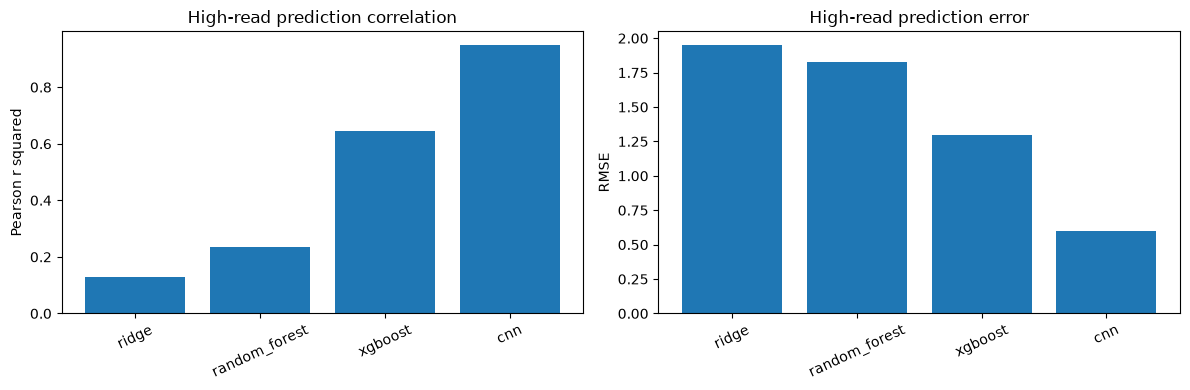

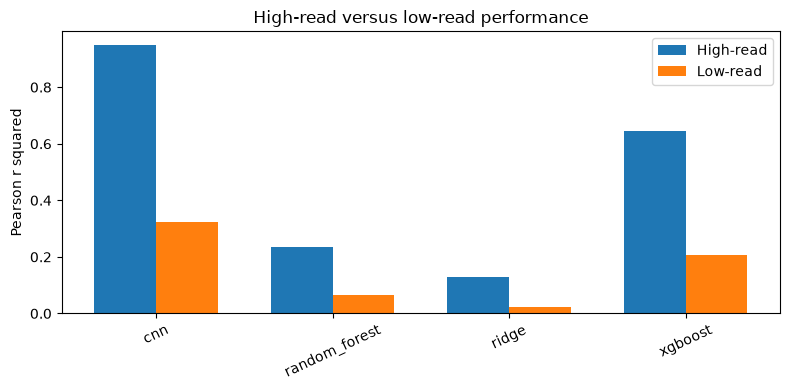

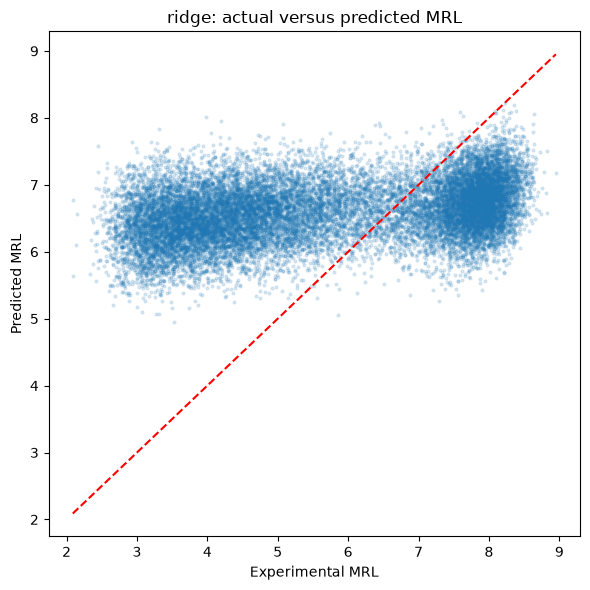

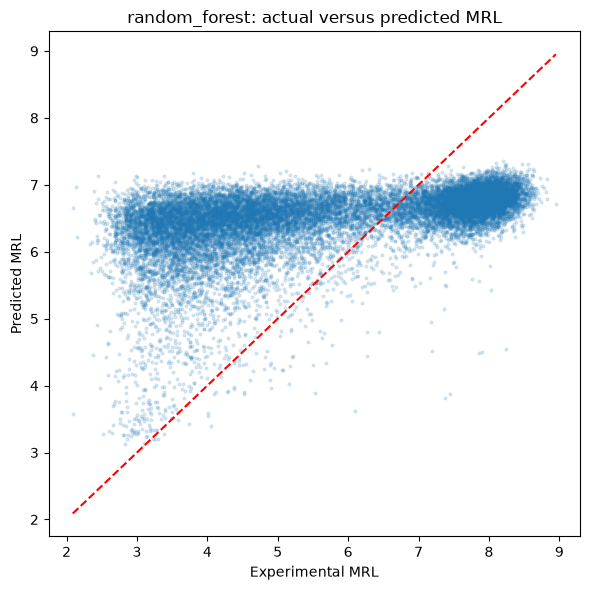

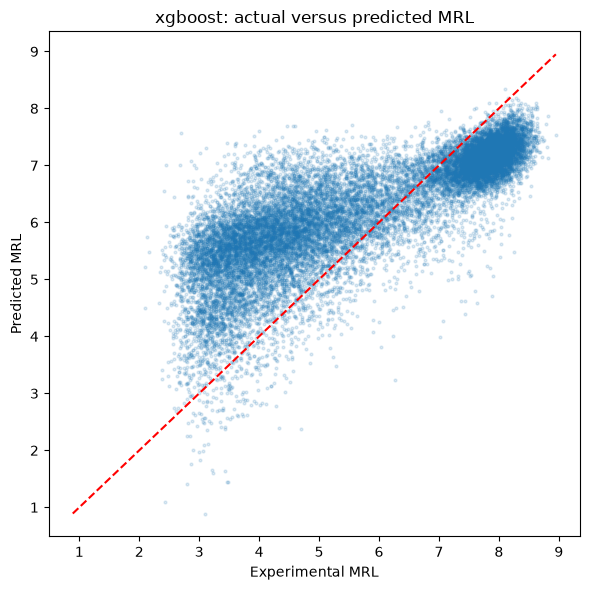

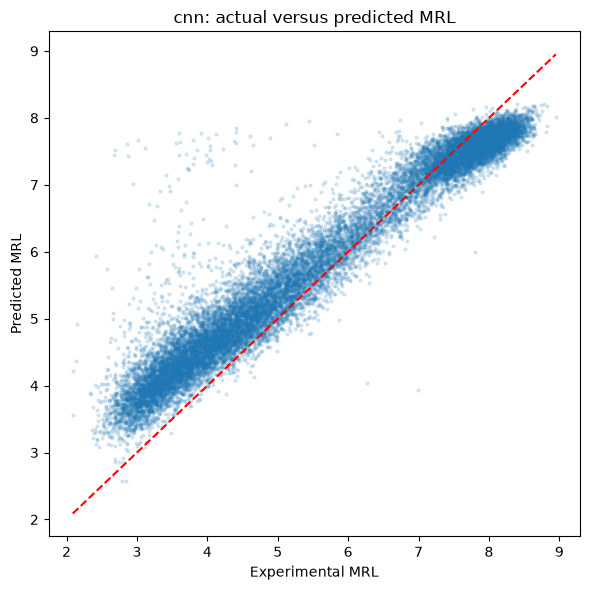

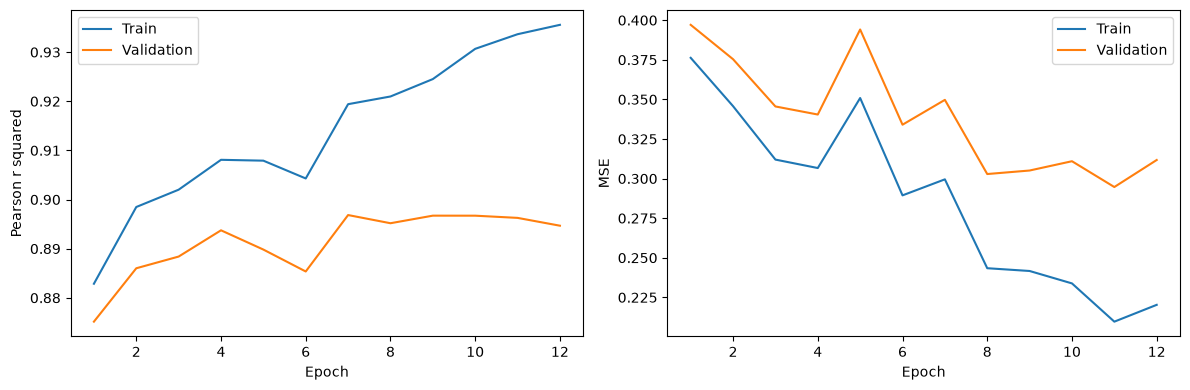

In [4]:
from src.pipeline import load_cnn_history, load_predictions
from src.visualization import (
    plot_actual_vs_predicted,
    plot_cnn_learning_curves,
    plot_model_comparison,
    plot_read_group_comparison,
)

# Plot overall model comparisons
plot_model_comparison(metrics, RESULTS_DIR / "model_comparison.png")
plot_read_group_comparison(metrics, RESULTS_DIR / "read_group_comparison.png")

# Plot predictions for each model
for model_name in models_to_train:
    predictions = load_predictions(model_name, "high_read_test")
    plot_actual_vs_predicted(
        predictions,
        model_name,
        RESULTS_DIR / model_name / "actual_vs_predicted.png",
    )

# Plot CNN learning curves
if "cnn" in models_to_train:
    cnn_history = load_cnn_history()
    plot_cnn_learning_curves(
        cnn_history,
        RESULTS_DIR / "cnn/training_curves.png",
    )